In [23]:
#Definicion de librerias

import qutip as qt
import numpy as np
import random

%matplotlib inline
from IPython.display import Image
from qutip import *
from qutip_qip.operations import *
from qutip_qip.circuit import QubitCircuit, Gate, CircuitSimulator


In [24]:
#Definición de los dos estados de la base 
psi_0=qt.basis(2,0)
psi_1=qt.basis(2,1)


#Definicion del estado inicial como superposicion de los estados de la base
#coeficientes
a=1
b=1

psi_superposition=(a*psi_0+b*psi_1).unit()

psi_superposition

Quantum object: dims=[[2], [1]], shape=(2, 1), type='ket', dtype=Dense
Qobj data =
[[0.70710678]
 [0.70710678]]

In [25]:
#Definicion de matrices de pauli

sigma_x=qt.sigmax()
sigma_y=qt.sigmay()
sigma_z=qt.sigmaz()

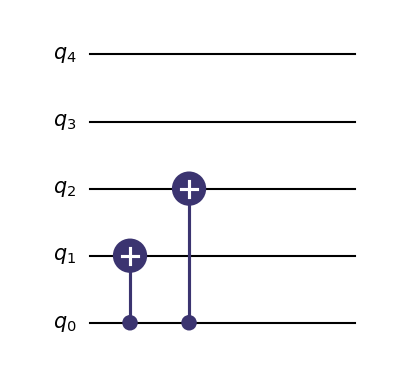

In [26]:
#ejercicio 7
#creamos un circuito de codificación de 3 qubits
q0=psi_superposition  # Estado |ψ>
q1=qt.basis(2, 0)  # Estado |0>
q2=qt.basis(2, 0)  # Estado |0>
q_total = tensor(q0, q1, q2, q1, q1)
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
qenc

In [27]:
U7=gate_sequence_product(qenc.propagators())
q_encoded7 = U7*q_total

In [28]:
#ejercicio7
#introducimos un error de bit-flip en uno de los qubits
error_op = [qt.qeye(2) for _ in range(5)]  # Operadores de error para cada qubit
flip_qubit = random.randint(0,2) # qubit to bit-flip
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmax()

errorstate = tensor(error_op) * q_encoded7
errorstate = errorstate.unit()
errorstate

Bit-flipping qubit 0


Quantum object: dims=[[2, 2, 2, 2, 2], [1]], shape=(32, 1), type='ket', dtype=Dense
Qobj data =
[[0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.70710678]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]
 [0.        ]]

In [29]:
#ejercicio 7
#definimos los operadores de control para la corrección de errores
op_Z1 = tensor(sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2), qt.qeye(2))
op_Z2 = tensor(qt.qeye(2), sigmaz(), sigmaz(), qt.qeye(2), qt.qeye(2))


#aplicamos los operadores de control al estado con error y calculamos los valores esperados

val_ZZI = round(expect(op_Z1, errorstate))
val_IZZ = round(expect(op_Z2, errorstate))

print(f" <Z Z I>: {val_ZZI:.0f}")
print(f" <I Z Z>: {val_IZZ:.0f}")

if val_ZZI == 1 and val_IZZ == 1:
    print("No error detected.")
elif val_ZZI == -1 and val_IZZ == 1:
    print("Error detected on qubit 0.")
elif val_ZZI == 1 and val_IZZ == -1:
    print("Error detected on qubit 2.")
elif val_ZZI == -1 and val_IZZ == -1:
    print("Error detected on qubit 1.")


 <Z Z I>: -1
 <I Z Z>: 1
Error detected on qubit 0.


In [30]:
q7ii= tensor(q0, q1, q2, q1, q1)
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
#añadir error con sigma x
##trabajo de jorge
qenc.add_gate("CNOT", controls=[1], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[1], targets=[4])
qenc.add_gate("CNOT", controls=[2], targets=[4])
qenc
##mirar ancillas
U7ii=gate_sequence_product(qenc.propagators())
q_encoded7ii = U7*q7ii

Bit-flipping qubit 0


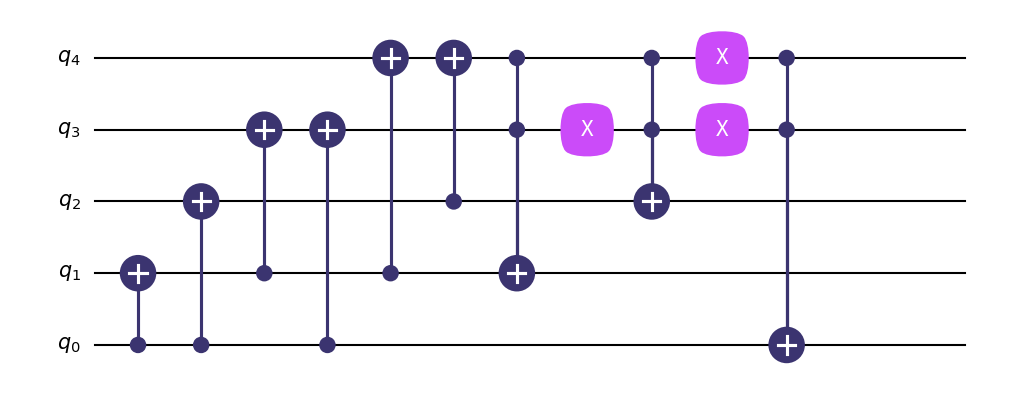

In [31]:
#ejercicio 8
#circuito
qenc = QubitCircuit(5, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
error_op = [qt.qeye(2) for _ in range(5)]  # Operadores de error para cada qubit
flip_qubit = random.randint(0,2) # qubit to bit-flip
print("Bit-flipping qubit {}".format(flip_qubit))
error_op[flip_qubit] *= sigmax()
qenc.add_gate("CNOT", controls=[1], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[1], targets=[4])
qenc.add_gate("CNOT", controls=[2], targets=[4])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[1])
qenc.add_gate("X", targets=[3])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[2])
qenc.add_gate("X", targets=[3])
qenc.add_gate("X", targets=[4])
qenc.add_gate("TOFFOLI", controls=[3,4], targets=[0])
qenc

In [32]:
#ejercicio 8
#implementación del circuito de corrección de errores sobre chi 
U8=gate_sequence_product(qenc.propagators())
q_encoded8=U8*q_total

#comprobación de si se ha corregido el error
val_ZZI = round(expect(op_Z1, q_encoded8))
val_IZZ = round(expect(op_Z2, q_encoded8))

print(f" <Z Z I>: {val_ZZI:.0f}")
print(f" <I Z Z>: {val_IZZ:.0f}")

if val_ZZI == 1 and val_IZZ == 1:
    print("se ha corregido el error.")
else:
    print("no se ha corregido el error.")

 <Z Z I>: 1
 <I Z Z>: 1
se ha corregido el error.


|000000000>: 0.707107+0j
|100000000>: 0.707107+0j


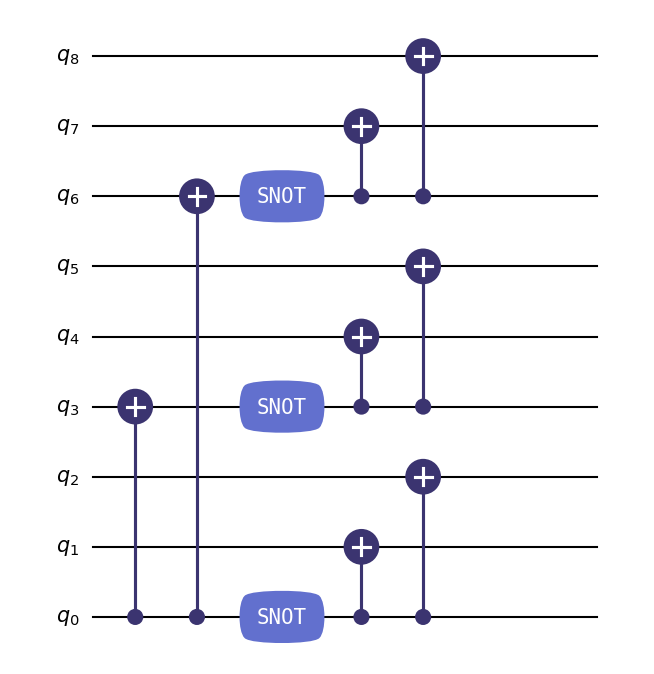

In [33]:
#ejercicio 10
#operadores O1 y O2 de control para detección de flip de fase (9 qubits)
psi_1=qt.tensor(psi_superposition,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0,psi_0)


#Mostramos este estado por pantalla 
coeficientes = psi_1.full().ravel()

for i, coef in enumerate(coeficientes):
    if abs(coef) > 1e-10:
        print(f"|{i:09b}>: {coef:.6g}")

qenc = QubitCircuit(9, reverse_states=False)
qenc.add_gate("CNOT", controls=[0], targets=[3])
qenc.add_gate("CNOT", controls=[0], targets=[6])
qenc.add_gate("SNOT", targets=[0])
qenc.add_gate("SNOT", targets=[3])
qenc.add_gate("SNOT", targets=[6])
qenc.add_gate("CNOT", controls=[6], targets=[7])
qenc.add_gate("CNOT", controls=[6], targets=[8])
qenc.add_gate("CNOT", controls=[3], targets=[4])
qenc.add_gate("CNOT", controls=[3], targets=[5])
qenc.add_gate("CNOT", controls=[0], targets=[1])
qenc.add_gate("CNOT", controls=[0], targets=[2])
U10=gate_sequence_product(qenc.propagators())
qenc

In [59]:
#introducimos un error de flip de fase en uno de los qubits

error_op = [qeye(2)]*9
phase_qubit = random.randint(0, 8) # qubit to phase-
print("Phase-flippping qubit {}".format(phase_qubit))
error_op[phase_qubit] *= sigmaz()

q_encoded10 = tensor(error_op) * U10*psi_1

#q_encoded10 = U10 * psi_1

# 2. Definir una lista de 9 identidades
#error_op = [qt.qeye(2)] * 9

# 3. Colocar el error en el cúbit
#error_op[8] = qt.sigmaz()  # o qt.sigmaz() para error de fase

# 4. Aplicar el producto tensor al estado
#q_encoded10 = qt.tensor(error_op) * q_encoded10

Phase-flippping qubit 2


In [60]:
O1=tensor(sigmax(), sigmax(), sigmax(), sigmax(),sigmax(), sigmax(), qt.qeye(2), qt.qeye(2), qt.qeye(2))
O2=tensor(qt.qeye(2), qt.qeye(2), qt.qeye(2), sigmax(), sigmax(), sigmax(), sigmax(), sigmax(), sigmax())


#aplicamos los operadores de control al estado con error y calculamos los valores esperados

val_O1 = round(expect(O1, q_encoded10))
val_O2 = round(expect(O2, q_encoded10))

print(f" <O1>: {val_O1:.0f}")
print(f" <O2>: {val_O2:.0f}")
if val_O1 == 1 and val_O2 == 1:
    print("No error detected.")
elif val_O1 == -1 and val_O2 == 1:
    print("Error detected on block 0.")
elif val_O1 == 1 and val_O2 == -1:
    print("Error detected on block 2.")
elif val_O1 == -1 and val_O2 == -1:
    print("Error detected on block 1.")

 <O1>: -1
 <O2>: 1
Error detected on block 0.


In [61]:
#arreglar el error de flip de fase
error_correccion= [qeye(2)]*9
error_correccion[phase_qubit] *= sigmaz()
q_encoded10 = tensor(error_correccion) * q_encoded10
val_O1 = round(expect(O1, q_encoded10))
val_O2 = round(expect(O2, q_encoded10))

print(f" <O1>: {val_O1:.0f}")
print(f" <O2>: {val_O2:.0f}")
if val_O1 == 1 and val_O2 == 1:
    print("No error detected.")
elif val_O1 == -1 and val_O2 == 1:
    print("Error detected on block 0.")
elif val_O1 == 1 and val_O2 == -1:
    print("Error detected on block 2.")
elif val_O1 == -1 and val_O2 == -1:
    print("Error detected on block 1.")

 <O1>: 1
 <O2>: 1
No error detected.
